# Jour 1 — Anatomie des données de marché

## Prix, OHLCV, rendements simples et rendements logarithmiques

**Question de marché :** comment transformer une série de prix brute en données propres et en rendements exploitables sans introduire d'erreur silencieuse ?

### Objectifs

- comprendre les champs Open, High, Low, Close, Adjusted Close et Volume ;
- télécharger et contrôler une série quotidienne ;
- calculer rendement simple et rendement logarithmique ;
- visualiser prix, volume, rendements et volatilité ;
- vérifier les identités financières avec des tests automatiques.

> Contenu éducatif uniquement — il ne s'agit pas d'un conseil d'investissement.

## 1. Installation

Exécutez la cellule suivante une seule fois par environnement. Redémarrez le kernel si l'installation le demande.

In [1]:
%pip install -q yfinance pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Imports et configuration graphique

On fixe les options d'affichage pour rendre le notebook lisible et reproductible.

In [2]:
from datetime import date
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import yfinance as yf
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("default")

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100})

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

TRADING_DAYS = 252

# yfinance utilise un cache persistant. On le place dans le projet afin que le
# notebook fonctionne aussi dans les environnements où le dossier utilisateur
# n'est pas accessible en écriture.
YF_CACHE_DIR = Path(".cache") / "yfinance"
YF_CACHE_DIR.mkdir(parents=True, exist_ok=True)
yf.set_tz_cache_location(str(YF_CACHE_DIR))

print(f"pandas   : {pd.__version__}")
print(f"NumPy    : {np.__version__}")
print(f"yfinance : {yf.__version__}")

pandas   : 3.0.1
NumPy    : 2.4.3
yfinance : 1.2.0


## 3. Paramètres de l'étude

Nous utilisons **SPY**, un ETF répliquant le S&P 500, car ses données quotidiennes sont liquides et faciles à interpréter. Vous pourrez ensuite remplacer le ticker par `QQQ`, `AAPL`, `EURUSD=X`, `GC=F` ou un autre instrument Yahoo Finance.

La borne `end` de `yfinance.download` est exclusive. On ajoute donc un jour pour demander les observations jusqu'à aujourd'hui.

In [6]:
from pathlib import Path

YF_CACHE_DIR = Path.cwd() / ".cache" / "yfinance"
YF_CACHE_DIR.mkdir(parents=True, exist_ok=True)

yf.set_tz_cache_location(str(YF_CACHE_DIR))

print("Version yfinance :", yf.__version__)
print("Cache yfinance   :", YF_CACHE_DIR.resolve())
print("Ticker           :", TICKER)
print("Période          :", START_DATE, "→", END_DATE)

Version yfinance : 1.2.0
Cache yfinance   : C:\Users\JulienRUIZ\Desktop\DAILY_GITHUB\.cache\yfinance
Ticker           : SPY
Période          : 2020-01-01 → 2026-11-09


## 4. Téléchargement des données brutes

Paramètres importants :

- `auto_adjust=False` conserve à la fois `Close` et `Adj Close` ;
- `actions=True` demande aussi les dividendes et splits lorsqu'ils sont disponibles ;
- `repair=True` demande à yfinance de tenter de corriger certaines anomalies d'unités ;
- `multi_level_index=False` évite un index de colonnes à plusieurs niveaux pour un seul ticker.

In [5]:
from pathlib import Path

YF_CACHE_DIR = Path.cwd() / ".cache" / "yfinance"
YF_CACHE_DIR.mkdir(parents=True, exist_ok=True)

yf.set_tz_cache_location(str(YF_CACHE_DIR))

print("Version yfinance :", yf.__version__)
print("Cache yfinance   :", YF_CACHE_DIR.resolve())
print("Ticker           :", TICKER)
print("Période          :", START_DATE, "→", END_DATE)

Version yfinance : 1.2.0
Cache yfinance   : C:\Users\JulienRUIZ\Desktop\DAILY_GITHUB\.cache\yfinance
Ticker           : SPY
Période          : 2020-01-01 → 2026-11-09


## 5. Lire une ligne OHLCV

- **Open** : premier prix négocié de la séance ;
- **High** : prix maximal de la séance ;
- **Low** : prix minimal de la séance ;
- **Close** : dernier prix officiel de la séance ;
- **Adj Close** : clôture ajustée des distributions et opérations sur titres ;
- **Volume** : quantité échangée selon la convention de la source.

Pour une analyse de performance sur une longue période, `Adj Close` est généralement plus pertinent que `Close`, car il prend en compte les dividendes et splits. Pour analyser le niveau effectivement coté à une date précise, `Close` reste utile.

In [7]:
download_error = None

try:
    raw = yf.download(
        tickers=TICKER,
        start=START_DATE,
        end=END_DATE,
        interval="1d",
        auto_adjust=False,
        actions=True,
        repair=False,
        keepna=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
except Exception as exc:
    download_error = exc
    raw = pd.DataFrame()


# Deuxième méthode si yf.download ne renvoie rien
if raw.empty:
    print("Premier téléchargement vide. Tentative avec Ticker.history...")

    try:
        raw = yf.Ticker(TICKER).history(
            start=START_DATE,
            end=END_DATE,
            interval="1d",
            auto_adjust=False,
            actions=True,
            repair=False,
            timeout=30,
            raise_errors=True,
        )
    except Exception as exc:
        raise RuntimeError(
            "Yahoo Finance n'est pas accessible depuis cet environnement.\n"
            f"Première erreur : {download_error}\n"
            f"Deuxième erreur : {type(exc).__name__}: {exc}"
        ) from exc


if raw.empty:
    raise RuntimeError(
        f"Aucune donnée disponible pour {TICKER} entre "
        f"{START_DATE} et {END_DATE}."
    )


# Protection contre les colonnes MultiIndex
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)


data = raw.copy()
data.index = pd.to_datetime(data.index)

# Retrait éventuel du fuseau horaire
if data.index.tz is not None:
    data.index = data.index.tz_localize(None)

data = data.sort_index()

# Protection si Adj Close n'est pas fourni
if "Adj Close" not in data.columns:
    data["Adj Close"] = data["Close"]


print("✅ Téléchargement réussi")
print(f"Nombre d'observations : {len(data):,}")
print(f"Première date          : {data.index.min().date()}")
print(f"Dernière date          : {data.index.max().date()}")

display(data.head())

✅ Téléchargement réussi
Nombre d'observations : 1,722
Première date          : 2020-01-02
Dernière date          : 2026-11-06


,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2020-01-02,295.3918,0.0000,324.8700,0.0000,324.8900,322.5300,323.5400,0.0000,59151200
2020-01-03,293.1549,0.0000,322.4100,0.0000,323.6400,321.1000,321.1600,0.0000,77709700
2020-01-06,294.2734,0.0000,323.6400,0.0000,323.7300,320.3600,320.4900,0.0000,55653900
2020-01-07,293.4460,0.0000,322.7300,0.0000,323.5400,322.2400,323.0200,0.0000,40496400
2020-01-08,295.0098,0.0000,324.4500,0.0000,325.7800,322.6700,322.9400,0.0000,68296000


## 6. Premier contrôle qualité

Avant tout calcul financier, on vérifie : ordre des dates, doublons, valeurs manquantes, volumes négatifs et cohérence entre Open, High, Low et Close.

In [8]:
def market_data_quality_report(df: pd.DataFrame) -> pd.Series:
    required = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    missing_columns = [column for column in required if column not in df.columns]

    if missing_columns:
        raise ValueError(f"Colonnes absentes : {missing_columns}")

    ohlc = df[["Open", "High", "Low", "Close"]].dropna()
    bad_high = (ohlc["High"] < ohlc[["Open", "Low", "Close"]].max(axis=1)).sum()
    bad_low = (ohlc["Low"] > ohlc[["Open", "High", "Close"]].min(axis=1)).sum()

    return pd.Series(
        {
            "observations": len(df),
            "dates_dupliquees": int(df.index.duplicated().sum()),
            "index_trie": bool(df.index.is_monotonic_increasing),
            "valeurs_manquantes": int(df[required].isna().sum().sum()),
            "volumes_negatifs": int((df["Volume"].dropna() < 0).sum()),
            "high_incoherents": int(bad_high),
            "low_incoherents": int(bad_low),
        },
        name="contrôle",
    )


quality_report = market_data_quality_report(data)
display(quality_report.to_frame())

,contrôle
observations,1722
dates_dupliquees,0
index_trie,True
valeurs_manquantes,0
volumes_negatifs,0
high_incoherents,0
low_incoherents,0


### Interprétation

Un rapport sans anomalie ne garantit pas que les prix sont économiquement corrects, mais il élimine plusieurs erreurs courantes. Une valeur manquante n'est pas automatiquement une erreur : elle peut correspondre à un jour férié ou à une suspension de cotation. Il ne faut jamais remplir un prix manquant sans comprendre sa cause.

## 7. Visualiser prix et volume

Le niveau des prix et le volume n'ont pas la même unité. On les place sur deux graphiques alignés plutôt que de les mélanger sur un même axe.

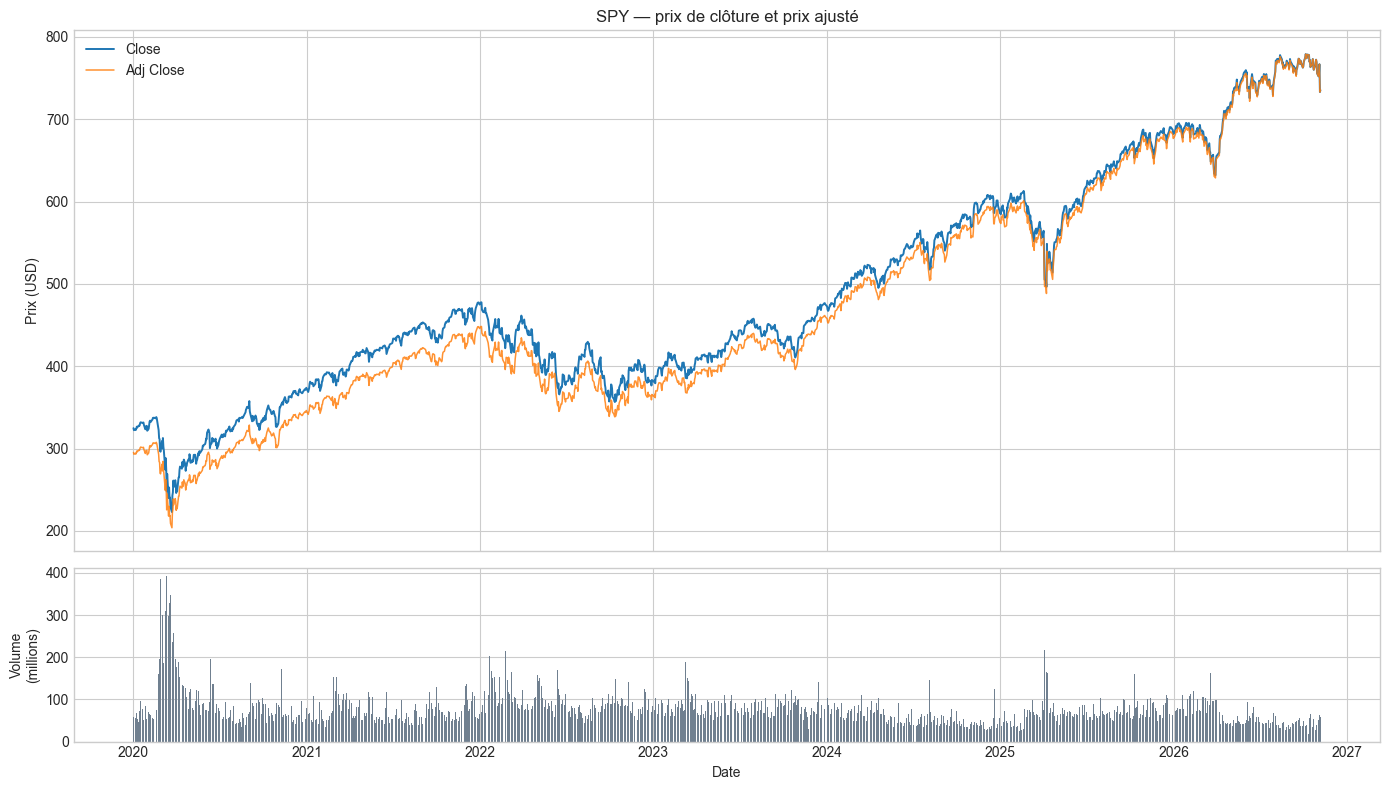

In [9]:
fig, (ax_price, ax_volume) = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax_price.plot(data.index, data["Close"], label="Close", color="tab:blue", linewidth=1.4)
ax_price.plot(
    data.index,
    data["Adj Close"],
    label="Adj Close",
    color="tab:orange",
    linewidth=1.1,
    alpha=0.85,
)
ax_price.set_title(f"{TICKER} — prix de clôture et prix ajusté")
ax_price.set_ylabel("Prix (USD)")
ax_price.legend()

ax_volume.bar(data.index, data["Volume"] / 1_000_000, color="slategray", width=1.0)
ax_volume.set_ylabel("Volume\n(millions)")
ax_volume.set_xlabel("Date")

fig.tight_layout()
plt.show()
plt.close(fig)

## 8. Amplitude intraday et facteur d'ajustement

L'amplitude intraday ci-dessous n'est pas un rendement d'investisseur : elle mesure simplement l'écart entre le plus haut et le plus bas relativement à l'ouverture. Le facteur `Adj Close / Close` révèle l'effet cumulé des ajustements.

,count,mean,std,min,25%,50%,75%,max
Open,"1,722.0000",490.8271,131.7265,228.1900,395.3525,448.4700,589.6375,778.7800
High,"1,722.0000",493.6000,131.7820,229.6800,398.2125,450.6950,592.7850,781.6200
Low,"1,722.0000",487.8214,131.5220,218.2600,392.6825,445.9000,585.3050,777.9600
Close,"1,722.0000",490.8994,131.6647,222.9500,395.8050,448.7600,590.2375,779.0900
Adj Close,"1,722.0000",473.1622,139.4025,203.9119,374.9463,424.7859,578.1382,779.0900
Volume,"1,722.0000","77,696,024.7967","38,952,047.4612","18,685,000.0000","54,264,275.0000","70,159,750.0000","90,126,675.0000","392,220,700.0000"
Intraday Range,"1,722.0000",0.0126,0.0096,0.0017,0.0069,0.0100,0.0148,0.1126
Adjustment Factor,"1,722.0000",0.9573,0.0268,0.9093,0.9331,0.9575,0.9807,1.0000


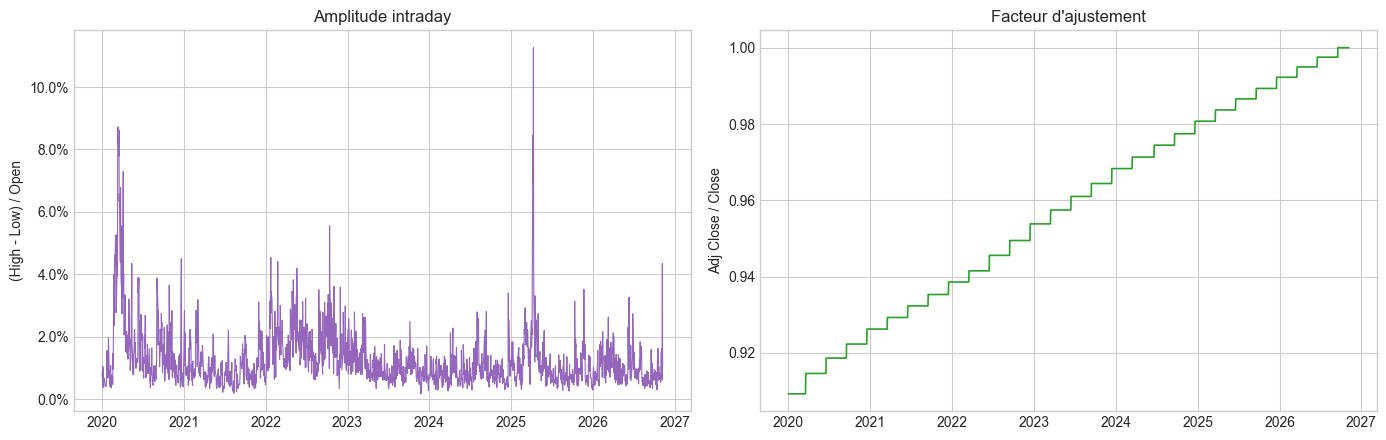

In [10]:
data["Intraday Range"] = (data["High"] - data["Low"]) / data["Open"]
data["Adjustment Factor"] = data["Adj Close"] / data["Close"]

summary_ohlcv = data[
    ["Open", "High", "Low", "Close", "Adj Close", "Volume", "Intraday Range", "Adjustment Factor"]
].describe().T

display(summary_ohlcv)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(data.index, data["Intraday Range"], color="tab:purple", linewidth=0.8)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_title("Amplitude intraday")
axes[0].set_ylabel("(High - Low) / Open")

axes[1].plot(data.index, data["Adjustment Factor"], color="tab:green", linewidth=1.2)
axes[1].set_title("Facteur d'ajustement")
axes[1].set_ylabel("Adj Close / Close")

fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Rendement simple et rendement logarithmique

Pour deux prix ajustés consécutifs, notés \(P_{t-1}\) et \(P_t\) :

\[
r_t = \frac{P_t}{P_{t-1}} - 1
\]

\[
g_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(1+r_t)
\]

- Le rendement simple s'agrège **par multiplication** : \(\prod_t(1+r_t)-1\).
- Le rendement logarithmique s'agrège **par addition** : \(\sum_t g_t\).
- Pour de petits mouvements, les deux sont proches, mais ils ne sont pas identiques.

In [11]:
prices = data["Adj Close"].astype(float)

# fill_method=None évite de transformer implicitement une valeur manquante en prix inchangé.
data["Simple Return"] = prices.pct_change(fill_method=None)
data["Log Return"] = np.log(prices / prices.shift(1))

returns = data[["Simple Return", "Log Return"]].dropna()
display(returns.head())

max_identity_error = (returns["Log Return"] - np.log1p(returns["Simple Return"])).abs().max()
print(f"Erreur maximale dans log(1 + rendement simple) : {max_identity_error:.3e}")

,Simple Return,Log Return
Date,,
2020-01-03,-0.0076,-0.0076
2020-01-06,0.0038,0.0038
2020-01-07,-0.0028,-0.0028
2020-01-08,0.0053,0.0053
2020-01-09,0.0068,0.0068


Erreur maximale dans log(1 + rendement simple) : 0.000e+00


## 10. Comparer graphiquement les deux rendements

Les différences deviennent plus visibles lors des journées de forte variation. Cette asymétrie est normale : un gain de 10 % suivi d'une perte de 10 % ne ramène pas au point de départ.

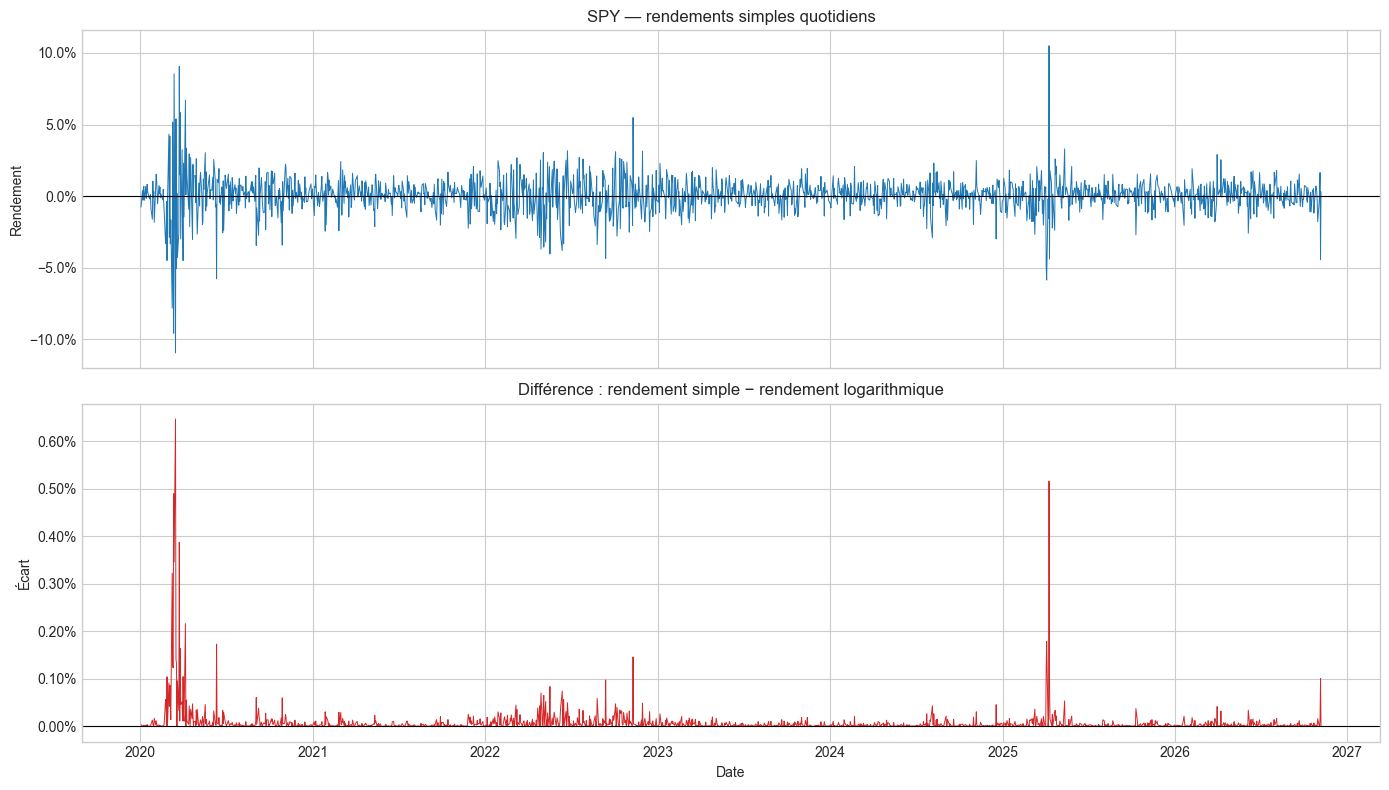

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(returns.index, returns["Simple Return"], color="tab:blue", linewidth=0.7)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_title(f"{TICKER} — rendements simples quotidiens")
axes[0].set_ylabel("Rendement")

difference = returns["Simple Return"] - returns["Log Return"]
axes[1].plot(difference.index, difference, color="tab:red", linewidth=0.7)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_title("Différence : rendement simple − rendement logarithmique")
axes[1].set_ylabel("Écart")
axes[1].set_xlabel("Date")

fig.tight_layout()
plt.show()
plt.close(fig)

## 11. Performance cumulée : deux méthodes, un même résultat

Nous reconstruisons la performance totale depuis la première observation disponible avec les deux conventions. Les courbes doivent être numériquement identiques, à l'arrondi machine près.

Erreur maximale entre les trois reconstructions : 3.997e-15


,Normalized Price,Growth from Simple,Growth from Log
Date,,,
2026-11-02,2.5461,2.5461,2.5461
2026-11-03,2.5537,2.5537,2.5537
2026-11-04,2.5959,2.5959,2.5959
2026-11-05,2.4815,2.4815,2.4815
2026-11-06,2.4892,2.4892,2.4892


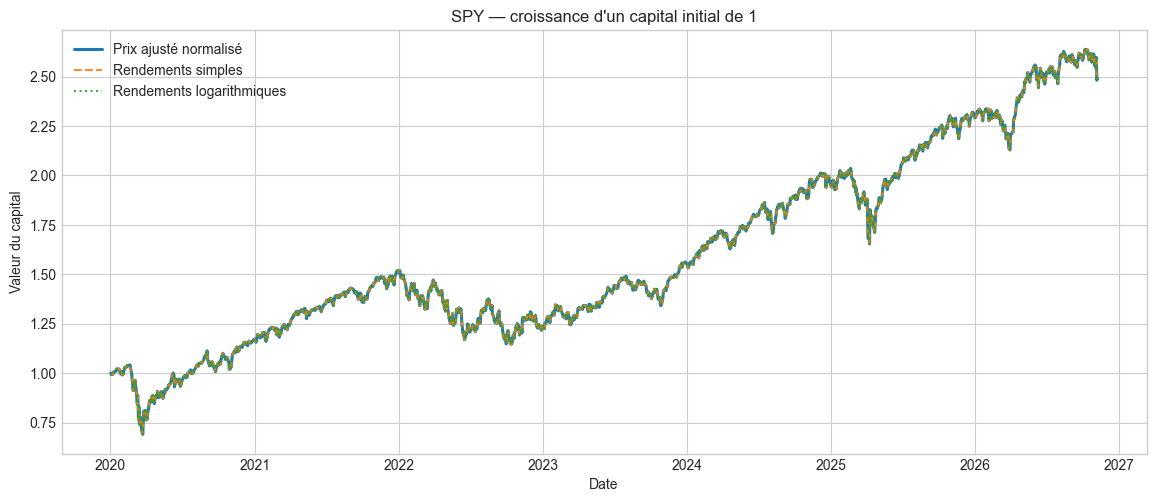

In [13]:
data["Growth from Simple"] = (1 + data["Simple Return"].fillna(0)).cumprod()
data["Growth from Log"] = np.exp(data["Log Return"].fillna(0).cumsum())
data["Normalized Price"] = prices / prices.iloc[0]

growth = data[["Normalized Price", "Growth from Simple", "Growth from Log"]]
max_growth_error = growth.sub(growth["Normalized Price"], axis=0).abs().to_numpy().max()

print(f"Erreur maximale entre les trois reconstructions : {max_growth_error:.3e}")
display(growth.tail())

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(growth.index, growth["Normalized Price"], label="Prix ajusté normalisé", linewidth=2.2)
ax.plot(growth.index, growth["Growth from Simple"], "--", label="Rendements simples", alpha=0.9)
ax.plot(growth.index, growth["Growth from Log"], ":", label="Rendements logarithmiques", alpha=0.9)
ax.set_title(f"{TICKER} — croissance d'un capital initial de 1")
ax.set_ylabel("Valeur du capital")
ax.set_xlabel("Date")
ax.legend()
plt.show()
plt.close(fig)

## 12. Statistiques descriptives

La volatilité annualisée est estimée par l'écart-type quotidien multiplié par \(\sqrt{252}\). C'est une convention, pas une loi de la nature : elle suppose notamment que l'échelle temporelle est raisonnablement stable.

In [14]:
simple_returns = data["Simple Return"].dropna()

statistics = pd.Series(
    {
        "Nombre de rendements": simple_returns.count(),
        "Moyenne quotidienne": simple_returns.mean(),
        "Médiane quotidienne": simple_returns.median(),
        "Volatilité quotidienne": simple_returns.std(ddof=1),
        "Volatilité annualisée": simple_returns.std(ddof=1) * np.sqrt(TRADING_DAYS),
        "Meilleure séance": simple_returns.max(),
        "Pire séance": simple_returns.min(),
        "Part de séances positives": (simple_returns > 0).mean(),
        "Rendement total": prices.iloc[-1] / prices.iloc[0] - 1,
    },
    name=TICKER,
)

display(statistics.to_frame())

,SPY
Nombre de rendements,"1,721.0000"
Moyenne quotidienne,0.0006
Médiane quotidienne,0.0009
Volatilité quotidienne,0.0126
Volatilité annualisée,0.2002
Meilleure séance,0.1050
Pire séance,-0.1094
Part de séances positives,0.5468
Rendement total,1.4892


## 13. Distribution et volatilité glissante

L'histogramme montre la fréquence des rendements. La volatilité glissante sur 21 séances représente environ un mois de bourse et permet d'observer les changements de régime.

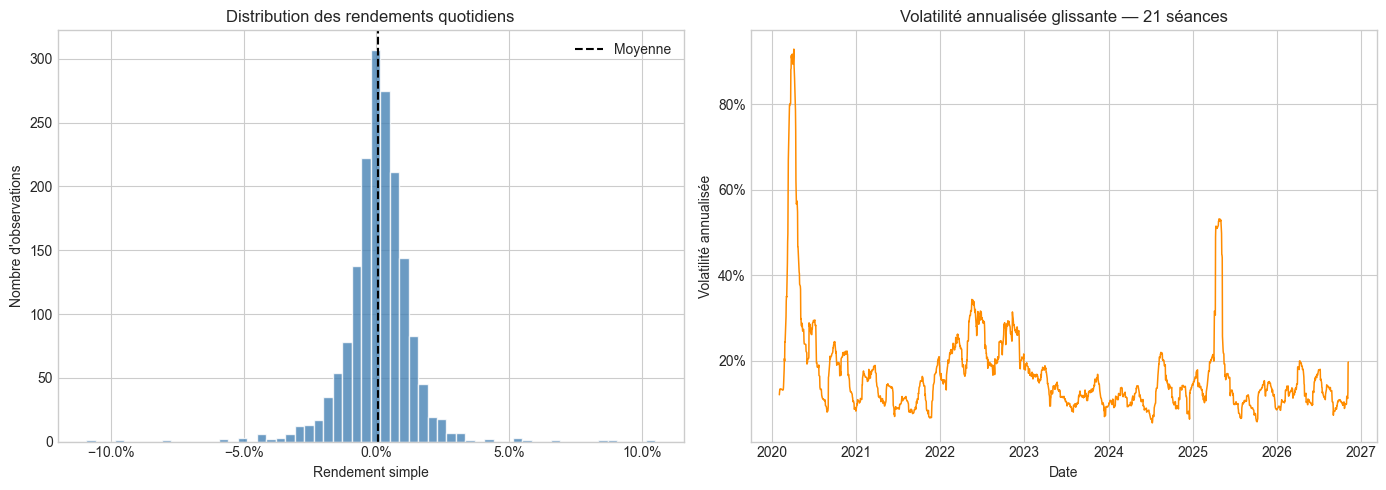

In [15]:
rolling_vol_21d = simple_returns.rolling(21).std(ddof=1) * np.sqrt(TRADING_DAYS)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(simple_returns, bins=60, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(simple_returns.mean(), color="black", linestyle="--", label="Moyenne")
axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_title("Distribution des rendements quotidiens")
axes[0].set_xlabel("Rendement simple")
axes[0].set_ylabel("Nombre d'observations")
axes[0].legend()

axes[1].plot(rolling_vol_21d.index, rolling_vol_21d, color="darkorange", linewidth=1.1)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_title("Volatilité annualisée glissante — 21 séances")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Volatilité annualisée")

fig.tight_layout()
plt.show()
plt.close(fig)

## 14. Analyse des séances extrêmes

Une moyenne ou une volatilité ne raconte pas toute l'histoire. Nous identifions les cinq meilleures et les cinq pires séances, puis nous affichons les données de marché correspondantes.

In [16]:
extreme_dates = pd.concat(
    [
        simple_returns.nsmallest(5).rename("Simple Return"),
        simple_returns.nlargest(5).rename("Simple Return"),
    ]
).sort_values()

extreme_days = data.loc[
    extreme_dates.index,
    ["Open", "High", "Low", "Close", "Adj Close", "Volume", "Simple Return", "Intraday Range"],
].sort_values("Simple Return")

display(
    extreme_days.style.format(
        {
            "Open": "${:,.2f}",
            "High": "${:,.2f}",
            "Low": "${:,.2f}",
            "Close": "${:,.2f}",
            "Adj Close": "${:,.2f}",
            "Volume": "{:,.0f}",
            "Simple Return": "{:.2%}",
            "Intraday Range": "{:.2%}",
        }
    )
)

,Open,High,Low,Close,Adj Close,Volume,Simple Return,Intraday Range
Date,,,,,,,,
2020-03-16 00:00:00,$241.18,$256.90,$237.36,$239.85,$218.09,"297,240,000",-10.94%,8.10%
2020-03-12 00:00:00,$256.00,$266.66,$247.68,$248.11,$225.60,"392,220,700",-9.57%,7.41%
2020-03-09 00:00:00,$275.30,$284.19,$273.45,$274.23,$249.35,"309,417,300",-7.81%,3.90%
2025-04-04 00:00:00,$523.67,$525.87,$505.06,$505.28,$497.04,"217,965,100",-5.85%,3.97%
2020-06-11 00:00:00,$311.46,$312.15,$300.01,$300.61,$274.94,"209,243,600",-5.76%,3.90%
2020-03-26 00:00:00,$249.52,$262.80,$249.05,$261.20,$238.90,"257,632,800",5.84%,5.51%
2020-04-06 00:00:00,$257.84,$267.00,$248.17,$264.86,$242.24,"188,061,200",6.72%,7.30%
2020-03-13 00:00:00,$263.09,$271.48,$248.52,$269.32,$244.88,"329,566,100",8.55%,8.73%
2020-03-24 00:00:00,$234.42,$244.10,$233.80,$243.15,$222.39,"235,494,500",9.06%,4.39%


### Questions d'analyse

1. Les séances les plus volatiles sont-elles regroupées dans le temps ?
2. Un volume élevé accompagne-t-il systématiquement un rendement extrême ?
3. Pourquoi `Close` et `Adj Close` peuvent-ils diverger ?
4. Pourquoi ne faut-il pas comparer directement le prix nominal de deux actifs différents ?

Prenez quelques minutes pour écrire vos réponses dans une nouvelle cellule Markdown avant de continuer.

## 15. Tests automatiques

Ces tests ne prouvent pas que la source est parfaite. Ils garantissent cependant que les principales relations utilisées dans le notebook sont cohérentes.

In [17]:
required_columns = {"Open", "High", "Low", "Close", "Adj Close", "Volume"}
ohlc_complete = data[["Open", "High", "Low", "Close"]].dropna()

assert required_columns.issubset(data.columns), "Une colonne OHLCV requise est absente."
assert not data.empty, "Le jeu de données est vide."
assert data.index.is_monotonic_increasing, "Les dates ne sont pas triées."
assert data.index.is_unique, "Les dates contiennent des doublons."
assert (data["Volume"].dropna() >= 0).all(), "Un volume négatif a été détecté."

assert (
    ohlc_complete["High"] >= ohlc_complete[["Open", "Low", "Close"]].max(axis=1)
).all(), "High est inférieur à un autre prix de la séance."

assert (
    ohlc_complete["Low"] <= ohlc_complete[["Open", "High", "Close"]].min(axis=1)
).all(), "Low est supérieur à un autre prix de la séance."

np.testing.assert_allclose(
    returns["Log Return"].to_numpy(),
    np.log1p(returns["Simple Return"].to_numpy()),
    rtol=1e-12,
    atol=1e-12,
)

np.testing.assert_allclose(
    data["Growth from Simple"].to_numpy(),
    data["Normalized Price"].to_numpy(),
    rtol=1e-10,
    atol=1e-10,
)

np.testing.assert_allclose(
    data["Growth from Log"].to_numpy(),
    data["Normalized Price"].to_numpy(),
    rtol=1e-10,
    atol=1e-10,
)

print("✅ Tous les tests du jour 1 sont passés.")

✅ Tous les tests du jour 1 sont passés.


## 16. Mini-exercice

Changez `TICKER` en haut du notebook et relancez toutes les cellules avec l'un des instruments suivants :

- `QQQ` — actions technologiques américaines ;
- `EURUSD=X` — taux de change euro/dollar ;
- `GC=F` — future sur l'or ;
- `^VIX` — indice de volatilité VIX.

Pour le nouvel instrument, répondez à trois questions :

1. Quelle est sa volatilité annualisée sur la période ?
2. Quelle est sa pire séance ?
3. La volatilité semble-t-elle stable ou organisée en régimes ?

**Attention :** les conventions de volume, horaires, ajustements et continuité des contrats diffèrent selon les classes d'actifs. Le même code ne signifie pas toujours la même réalité économique.

## 17. Conclusion

À retenir :

- une série de prix doit être contrôlée avant d'être analysée ;
- `Close` et `Adj Close` répondent à des questions différentes ;
- les rendements simples se composent par multiplication ;
- les rendements logarithmiques s'additionnent dans le temps ;
- une visualisation doit toujours préciser unité, fréquence et convention ;
- des tests simples évitent de nombreuses erreurs silencieuses.

**Prochaine étape — Jour 2 :** capitalisation, performance cumulée, CAGR et drawdowns.

### Références

- Documentation officielle `yfinance.download` : https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html
- Documentation officielle `pandas.DataFrame.pct_change` : https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html